# 04 — Đánh giá mô hình cuối cùng

Chọn ngưỡng F1 trên validation của rf_leaf2, refit cùng cấu hình trên toàn bộ train giai đoạn 2. Chỉ đọc test sau khi đã cố định mô hình và ngưỡng.

## 1. Thư viện và đường dẫn

In [1]:
from pathlib import Path
from time import perf_counter
import hashlib
import json
import platform
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, f1_score,
    precision_recall_curve, precision_score, recall_score,
    roc_auc_score, roc_curve,
)
from sklearn.model_selection import train_test_split

In [2]:
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", font="DejaVu Sans")
pd.set_option("display.max_columns", 20)

## 2. Xác nhận rf_leaf2 từ giai đoạn 3

In [3]:
with (PROJECT_ROOT / "notebooks" / "03_model_training.ipynb").open(encoding="utf-8") as file:
    stage3_notebook = json.load(file)
for cell in stage3_notebook["cells"]:
    source = "".join(cell["source"])
    if cell["cell_type"] == "code" and ("rf_baseline =" in source or "rf_trial =" in source):
        print(source, "\n")

with (REPORTS_DIR / "training_metadata.json").open(encoding="utf-8") as file:
    training_metadata = json.load(file)
assert training_metadata["selected_candidate_id"] == "rf_leaf2"
selected_info = next(item for item in training_metadata["candidates"] if item["candidate_id"] == "rf_leaf2")
candidate_path = PROJECT_ROOT / selected_info["path"]
candidate = joblib.load(candidate_path)
assert isinstance(candidate, RandomForestClassifier)
rf_parameters = candidate.get_params(deep=False)
assert all(rf_parameters[name] == value for name, value in selected_info["parameters"].items())
display(pd.Series(rf_parameters, name="Giá trị").to_frame())

rf_baseline = RandomForestClassifier(
    n_estimators=100, class_weight="balanced", random_state=42, n_jobs=-1,
)
train_candidate("rf_leaf1", "Random Forest", rf_baseline) 

rf_trial = clone(rf_baseline).set_params(min_samples_leaf=2)
train_candidate("rf_leaf2", "Random Forest", rf_trial) 



,Giá trị
bootstrap,True
ccp_alpha,0.0
class_weight,balanced
criterion,gini
max_depth,None
max_features,sqrt
max_leaf_nodes,None
max_samples,None
min_impurity_decrease,0.0
min_samples_leaf,2


In [4]:
stage3_results = pd.read_csv(REPORTS_DIR / "validation_results.csv", float_precision="round_trip")
display(stage3_results.loc[stage3_results["candidate_id"].eq("rf_leaf2")])

,candidate_id,model,Precision,Recall,F1,AP,TN,FP,FN,TP,fit_seconds,predict_seconds,threshold,warning_count,parameters
0,rf_leaf2,Random Forest,0.954545,0.828947,0.887324,0.877781,45317,3,13,63,15.954655,0.081252,0.5,0,"{""class_weight"": ""balanced"", ""max_depth"": null..."


## 3. Đọc train và tái tạo validation

In [5]:
train_paths = [PROCESSED_DIR / "X_train_raw.csv", PROCESSED_DIR / "y_train.csv"]
for path in train_paths:
    if not path.is_file():
        raise FileNotFoundError(f"Thiếu file: {path}")
    with path.open("rb") as file:
        expected_hash = training_metadata["source_sha256"][str(path.relative_to(PROJECT_ROOT))]
        assert hashlib.file_digest(file, "sha256").hexdigest() == expected_hash

X_train_raw = pd.read_csv(train_paths[0], float_precision="round_trip")
y_train = pd.read_csv(train_paths[1])["Class"]
feature_columns = training_metadata["feature_columns"]
assert feature_columns == ["Time", *[f"V{i}" for i in range(1, 29)], "Amount"]
assert X_train_raw.columns.tolist() == feature_columns == candidate.feature_names_in_.tolist()
assert X_train_raw.index.equals(y_train.index)
assert X_train_raw.notna().all().all() and y_train.notna().all()
assert np.isfinite(X_train_raw.to_numpy()).all()
assert set(y_train.unique()) == {0, 1}
assert not X_train_raw.duplicated().any()
print("Train giai đoạn 2:", X_train_raw.shape, y_train.shape)
display(y_train.value_counts().sort_index().rename("Số lượng").to_frame())

Train giai đoạn 2: (226980, 30) (226980,)


,Số lượng
Class,
0,226602
1,378


In [6]:
assert training_metadata["validation_size"] == 0.2
assert training_metadata["random_state"] == 42
X_training, X_validation, y_training, y_validation = train_test_split(
    X_train_raw, y_train, test_size=0.2, stratify=y_train, random_state=42,
)
with np.load(REPORTS_DIR / "training_validation_indices.npz") as saved_split:
    np.testing.assert_array_equal(X_training.index, saved_split["training_indices"])
    np.testing.assert_array_equal(X_validation.index, saved_split["validation_indices"])
assert X_training.index.intersection(X_validation.index).empty

split_summary = pd.DataFrame({
    "Số dòng": [len(X_train_raw), len(X_training), len(X_validation)],
    "Số đặc trưng": [X_train_raw.shape[1], X_training.shape[1], X_validation.shape[1]],
    "Class 0": [y_train.eq(0).sum(), y_training.eq(0).sum(), y_validation.eq(0).sum()],
    "Class 1": [y_train.eq(1).sum(), y_training.eq(1).sum(), y_validation.eq(1).sum()],
}, index=["Train giai đoạn 2", "Training", "Validation"])
display(split_summary)

,Số dòng,Số đặc trưng,Class 0,Class 1
Train giai đoạn 2,226980,30,226602,378
Training,181584,30,181282,302
Validation,45396,30,45320,76


In [7]:
validation_probabilities = candidate.predict_proba(X_validation)[:, 1]
saved_validation = pd.read_csv(REPORTS_DIR / "validation_predictions.csv", float_precision="round_trip")
np.testing.assert_array_equal(saved_validation["row_index_in_stage2_train"], X_validation.index)
np.testing.assert_array_equal(saved_validation["Class"], y_validation.to_numpy())
np.testing.assert_allclose(validation_probabilities, saved_validation["rf_leaf2"], rtol=0, atol=1e-12)
print("Validation và xác suất rf_leaf2 khớp giai đoạn 3.")

Validation và xác suất rf_leaf2 khớp giai đoạn 3.


## 4. Chọn ngưỡng trên validation

Thử 0.05–0.95, bước 0.01. Nếu nhiều ngưỡng cùng F1 cao nhất, chọn ngưỡng gần 0.5 nhất; nếu vẫn bằng khoảng cách, chọn ngưỡng nhỏ hơn.

In [8]:
thresholds = np.arange(5, 96) / 100
threshold_rows = []
for threshold in thresholds:
    predictions = (validation_probabilities >= threshold).astype(int)
    threshold_rows.append({
        "threshold": float(threshold),
        "Precision": precision_score(y_validation, predictions, zero_division=0),
        "Recall": recall_score(y_validation, predictions, zero_division=0),
        "F1": f1_score(y_validation, predictions, zero_division=0),
    })
threshold_results = pd.DataFrame(threshold_rows)
assert len(threshold_results) == 91 and threshold_results["threshold"].eq(0.5).any()
max_f1 = threshold_results["F1"].max()
tied_thresholds = threshold_results.loc[threshold_results["F1"].eq(max_f1)].copy()
tied_thresholds["distance_to_0.5"] = (tied_thresholds["threshold"] - 0.5).abs().round(2)
best_threshold_row = tied_thresholds.sort_values(["distance_to_0.5", "threshold"]).iloc[0]
selected_threshold = float(best_threshold_row["threshold"])
print(f"Ngưỡng được chọn từ validation: {selected_threshold:.2f}")
display(tied_thresholds.round(4))
display(threshold_results.loc[threshold_results["threshold"].isin([0.5, selected_threshold])].round(4))

Ngưỡng được chọn từ validation: 0.37


,threshold,Precision,Recall,F1,distance_to_0.5
30,0.35,0.942,0.8553,0.8966,0.15
31,0.36,0.942,0.8553,0.8966,0.14
32,0.37,0.942,0.8553,0.8966,0.13


,threshold,Precision,Recall,F1
32,0.37,0.9420,0.8553,0.8966
45,0.50,0.9545,0.8289,0.8873


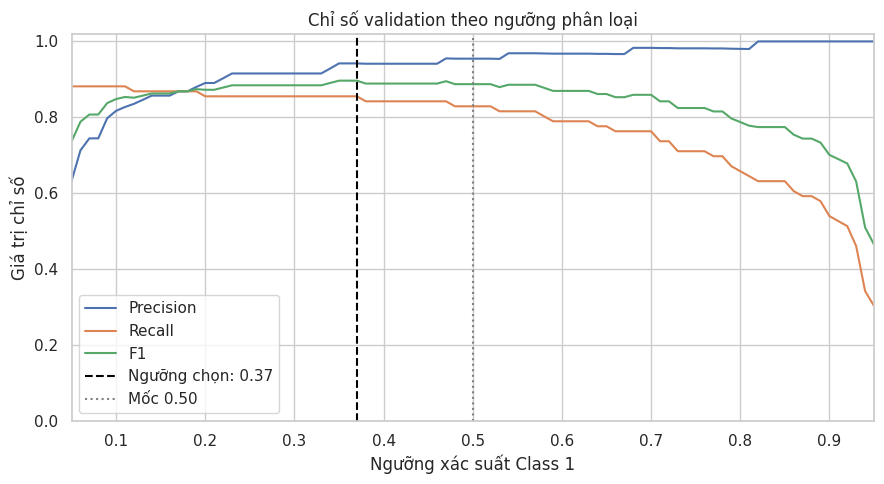

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
for metric in ["Precision", "Recall", "F1"]:
    ax.plot(threshold_results["threshold"], threshold_results[metric], label=metric)
ax.axvline(selected_threshold, color="black", linestyle="--", label=f"Ngưỡng chọn: {selected_threshold:.2f}")
ax.axvline(0.5, color="gray", linestyle=":", label="Mốc 0.50")
ax.set(title="Chỉ số validation theo ngưỡng phân loại", xlabel="Ngưỡng xác suất Class 1", ylabel="Giá trị chỉ số", xlim=(0.05, 0.95), ylim=(0, 1.02))
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_validation_thresholds.png", dpi=160, bbox_inches="tight")
plt.show()

In [10]:
def evaluate_threshold(y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    return {
        "threshold": float(threshold),
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "AP": average_precision_score(y_true, probabilities),
        "ROC_AUC": roc_auc_score(y_true, probabilities),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }

In [11]:
validation_metrics = pd.DataFrame([
    {"setting": "default_0.5", **evaluate_threshold(y_validation, validation_probabilities, 0.5)},
    {"setting": "selected_validation_f1", **evaluate_threshold(y_validation, validation_probabilities, selected_threshold)},
])
display(validation_metrics.round(4))

,setting,threshold,Accuracy,Precision,Recall,F1,AP,ROC_AUC,TN,FP,FN,TP
0,default_0.5,0.50,0.9996,0.9545,0.8289,0.8873,0.8778,0.9524,45317,3,13,63
1,selected_validation_f1,0.37,0.9997,0.9420,0.8553,0.8966,0.8778,0.9524,45316,4,11,65


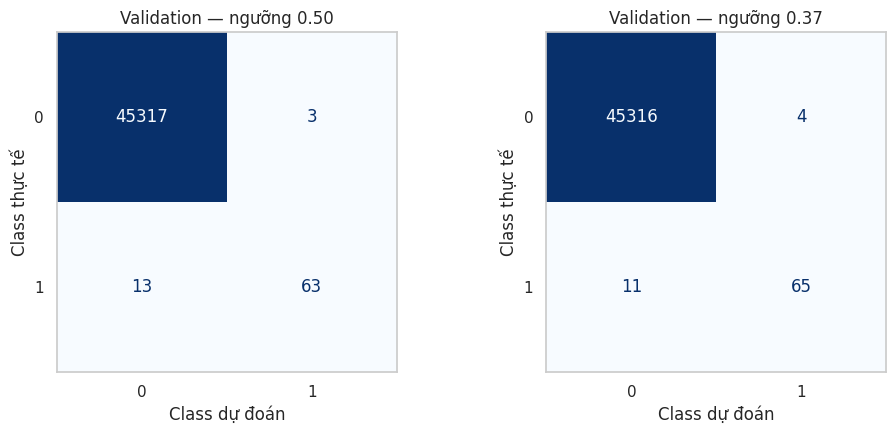

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for threshold, ax in zip([0.5, selected_threshold], axes):
    predictions = (validation_probabilities >= threshold).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_validation, predictions, labels=[0, 1], display_labels=[0, 1],
        cmap="Blues", values_format="d", colorbar=False, ax=ax,
    )
    ax.set(title=f"Validation — ngưỡng {threshold:.2f}", xlabel="Class dự đoán", ylabel="Class thực tế")
    ax.grid(False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_validation_confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. Cố định quyết định và refit trên toàn bộ train

Dùng nguyên bộ tham số của candidate đã xác nhận. Random Forest nhận 30 đặc trưng thô, không dùng StandardScaler. Không đổi ngưỡng sau khi refit hoặc xem test.

In [13]:
threshold_config = {
    "threshold": selected_threshold,
    "positive_class": 1,
    "decision_rule": "predict Class 1 when probability >= threshold",
    "selected_on": "stage3 validation; original rf_leaf2 candidate",
    "selection_metric": "F1",
    "search_start": 0.05, "search_stop": 0.95, "search_step": 0.01,
    "tie_break": "closest to 0.5; then smaller threshold",
    "validation_f1": float(best_threshold_row["F1"]),
}
with (MODELS_DIR / "threshold.json").open("w", encoding="utf-8") as file:
    json.dump(threshold_config, file, ensure_ascii=False, indent=2, allow_nan=False)
threshold_results.to_csv(REPORTS_DIR / "validation_threshold_search.csv", index=False)
validation_metrics.to_csv(REPORTS_DIR / "validation_threshold_metrics.csv", index=False)
print(f"Đã cố định ngưỡng {selected_threshold:.2f} trước khi đọc test.")

Đã cố định ngưỡng 0.37 trước khi đọc test.


In [14]:
final_model = RandomForestClassifier(**rf_parameters)
assert final_model.get_params() == candidate.get_params()
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    start = perf_counter()
    final_model.fit(X_train_raw, y_train)
    fit_seconds = perf_counter() - start
fit_warnings = [{"category": item.category.__name__, "message": str(item.message)} for item in caught]
assert final_model.n_features_in_ == 30
assert final_model.feature_names_in_.tolist() == feature_columns
assert final_model.classes_.tolist() == [0, 1]
print(f"Refit trên {len(X_train_raw):,} giao dịch: {fit_seconds:.2f} giây.")
print("Cảnh báo khi fit:", fit_warnings)

Refit trên 226,980 giao dịch: 24.08 giây.
Cảnh báo khi fit: []


## 6. Đọc và kiểm tra test

Từ đây chỉ đánh giá mô hình và ngưỡng đã cố định. Kết quả ở ngưỡng 0.5 là mốc tham khảo, không dùng để chọn lại ngưỡng.

In [15]:
X_test_raw = pd.read_csv(PROCESSED_DIR / "X_test_raw.csv", float_precision="round_trip")
y_test = pd.read_csv(PROCESSED_DIR / "y_test.csv")["Class"]
assert X_test_raw.columns.tolist() == feature_columns
assert X_test_raw.shape[1] == 30 and X_test_raw.index.equals(y_test.index)
assert X_test_raw.notna().all().all() and y_test.notna().all()
assert np.isfinite(X_test_raw.to_numpy()).all()
assert set(y_test.unique()) == {0, 1}
assert X_train_raw.merge(X_test_raw, on=feature_columns, how="inner").empty
with (MODELS_DIR / "threshold.json").open(encoding="utf-8") as file:
    assert json.load(file)["threshold"] == selected_threshold

print("X_test_raw:", X_test_raw.shape, "y_test:", y_test.shape)
display(pd.DataFrame({"Train": y_train.value_counts(), "Test": y_test.value_counts()}).sort_index())

X_test_raw: (56746, 30) y_test: (56746,)


,Train,Test
Class,,
0,226602,56651
1,378,95


## 7. Đánh giá test

In [16]:
start = perf_counter()
test_probabilities = final_model.predict_proba(X_test_raw)[:, 1]
predict_seconds = perf_counter() - start
assert np.isfinite(test_probabilities).all()
assert ((test_probabilities >= 0) & (test_probabilities <= 1)).all()
test_predictions = (test_probabilities >= selected_threshold).astype(int)

test_metrics = pd.DataFrame([
    {"setting": "selected_validation_f1", **evaluate_threshold(y_test, test_probabilities, selected_threshold)},
    {"setting": "default_0.5", **evaluate_threshold(y_test, test_probabilities, 0.5)},
])
display(test_metrics.round(4))
selected_test_metrics = test_metrics.iloc[0]
print(f"TP — phát hiện đúng gian lận: {int(selected_test_metrics['TP'])}")
print(f"FN — gian lận bị bỏ sót: {int(selected_test_metrics['FN'])}")
print(f"FP — giao dịch bình thường bị cảnh báo nhầm: {int(selected_test_metrics['FP'])}")
print(f"TN — giao dịch bình thường nhận diện đúng: {int(selected_test_metrics['TN'])}")

,setting,threshold,Accuracy,Precision,Recall,F1,AP,ROC_AUC,TN,FP,FN,TP
0,selected_validation_f1,0.37,0.9995,0.9589,0.7368,0.8333,0.8128,0.9293,56648,3,25,70
1,default_0.5,0.50,0.9995,0.9718,0.7263,0.8313,0.8128,0.9293,56649,2,26,69


TP — phát hiện đúng gian lận: 70
FN — gian lận bị bỏ sót: 25
FP — giao dịch bình thường bị cảnh báo nhầm: 3
TN — giao dịch bình thường nhận diện đúng: 56648


In [17]:
print(classification_report(
    y_test, test_predictions, labels=[0, 1],
    target_names=["Class 0 - Bình thường", "Class 1 - Gian lận"],
    digits=4, zero_division=0,
))
classification_table = pd.DataFrame(classification_report(
    y_test, test_predictions, labels=[0, 1],
    target_names=["Class 0", "Class 1"], output_dict=True, zero_division=0,
)).T.drop(index="accuracy")

                       precision    recall  f1-score   support

Class 0 - Bình thường     0.9996    0.9999    0.9998     56651
   Class 1 - Gian lận     0.9589    0.7368    0.8333        95

             accuracy                         0.9995     56746
            macro avg     0.9792    0.8684    0.9165     56746
         weighted avg     0.9995    0.9995    0.9995     56746



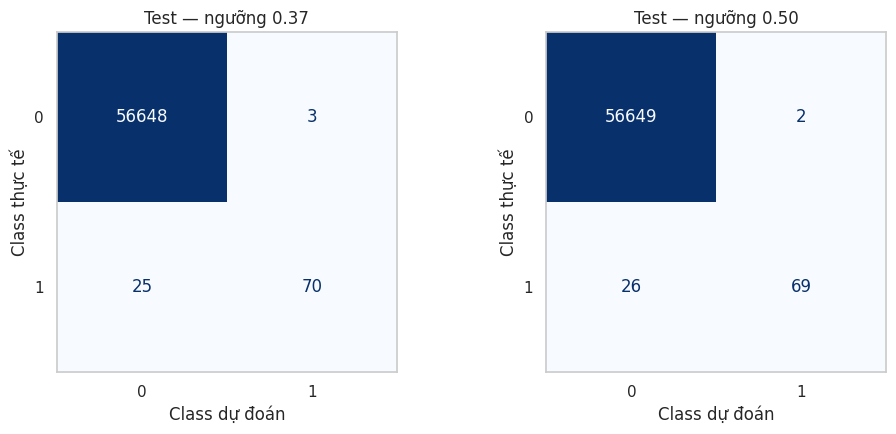

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for threshold, ax in zip([selected_threshold, 0.5], axes):
    predictions = (test_probabilities >= threshold).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, labels=[0, 1], display_labels=[0, 1],
        cmap="Blues", values_format="d", colorbar=False, ax=ax,
    )
    ax.set(title=f"Test — ngưỡng {threshold:.2f}", xlabel="Class dự đoán", ylabel="Class thực tế")
    ax.grid(False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_test_confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()

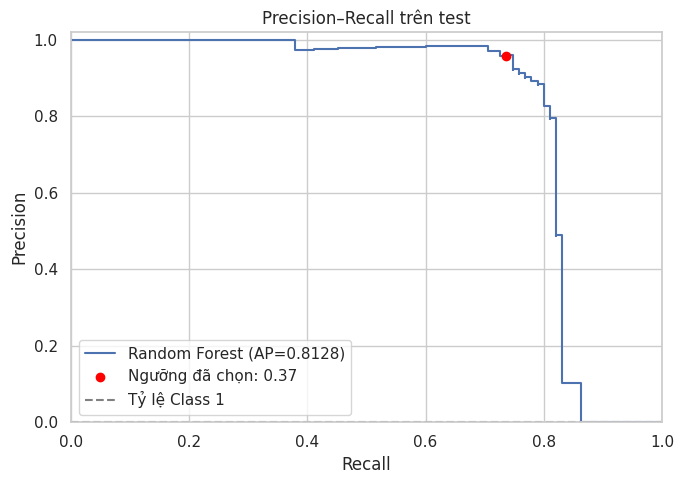

In [19]:
precision, recall, _ = precision_recall_curve(y_test, test_probabilities)
fig, ax = plt.subplots(figsize=(7, 5))
ax.step(recall, precision, where="post", label=f"Random Forest (AP={selected_test_metrics['AP']:.4f})")
ax.scatter(selected_test_metrics["Recall"], selected_test_metrics["Precision"], color="red", zorder=3, label=f"Ngưỡng đã chọn: {selected_threshold:.2f}")
ax.axhline(y_test.mean(), color="gray", linestyle="--", label="Tỷ lệ Class 1")
ax.set(title="Precision–Recall trên test", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_test_precision_recall.png", dpi=160, bbox_inches="tight")
plt.show()

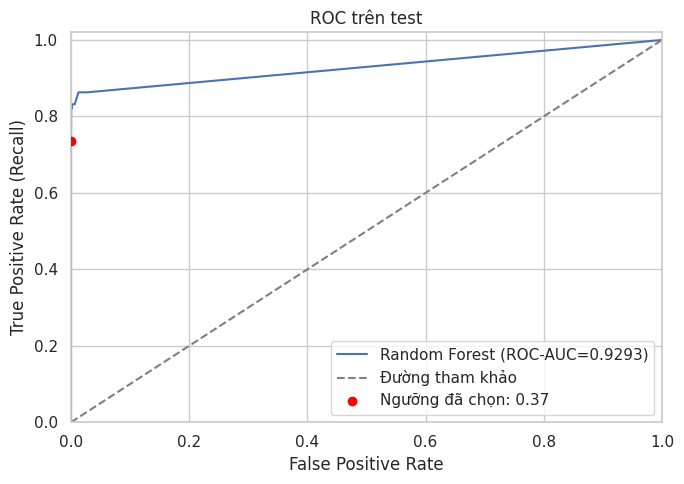

In [20]:
fpr, tpr, _ = roc_curve(y_test, test_probabilities)
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(fpr, tpr, label=f"Random Forest (ROC-AUC={selected_test_metrics['ROC_AUC']:.4f})")
ax.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Đường tham khảo")
ax.scatter(selected_test_metrics["FP"] / y_test.eq(0).sum(), selected_test_metrics["Recall"], color="red", zorder=3, label=f"Ngưỡng đã chọn: {selected_threshold:.2f}")
ax.set(title="ROC trên test", xlabel="False Positive Rate", ylabel="True Positive Rate (Recall)", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_test_roc.png", dpi=160, bbox_inches="tight")
plt.show()

## 8. Đối chiếu validation và test

Validation dùng candidate fit trên training subset; test dùng mô hình refit toàn bộ train. Đây là đối chiếu tham khảo giữa hai mô hình đã fit khác nhau, không phải đánh giá cùng một mô hình trên hai tập.

In [21]:
selected_validation_metrics = validation_metrics.loc[validation_metrics["setting"].eq("selected_validation_f1")].iloc[0]
comparison = pd.DataFrame([
    {"dataset": "Validation", "fit_scope": "Training subset", "fit_rows": len(X_training), **selected_validation_metrics.to_dict()},
    {"dataset": "Test", "fit_scope": "Full stage2 train", "fit_rows": len(X_train_raw), **selected_test_metrics.to_dict()},
])
display(comparison[["dataset", "fit_scope", "fit_rows", "threshold", "Precision", "Recall", "F1", "AP"]].round(4))

,dataset,fit_scope,fit_rows,threshold,Precision,Recall,F1,AP
0,Validation,Training subset,181584,0.37,0.9420,0.8553,0.8966,0.8778
1,Test,Full stage2 train,226980,0.37,0.9589,0.7368,0.8333,0.8128


## 9. Lưu mô hình và các file cho giai đoạn sau

Đầu vào dự đoán là DataFrame thô theo `features.json`; không dùng scaler. Nhãn gian lận được xác định bằng `predict_proba` và ngưỡng trong `threshold.json`, không dùng ngưỡng mặc định của `predict`.

In [22]:
BEST_MODEL_PATH = MODELS_DIR / "best_model.joblib"
joblib.dump(final_model, BEST_MODEL_PATH, compress=3)
with (MODELS_DIR / "features.json").open("w", encoding="utf-8") as file:
    json.dump(feature_columns, file, ensure_ascii=False, indent=2)

test_metrics.to_csv(REPORTS_DIR / "test_metrics.csv", index=False)
comparison.to_csv(REPORTS_DIR / "validation_test_comparison.csv", index=False)
classification_table.to_csv(REPORTS_DIR / "test_classification_report.csv", index_label="label")
pd.DataFrame({
    "row_index_in_stage2_test": X_test_raw.index,
    "Class": y_test.to_numpy(),
    "probability_class_1": test_probabilities,
    "prediction_selected_threshold": test_predictions,
}).to_csv(REPORTS_DIR / "test_predictions.csv", index=False)
pd.DataFrame(fit_warnings, columns=["category", "message"]).to_csv(REPORTS_DIR / "final_training_warnings.csv", index=False)

In [23]:
evaluation_metadata = {
    "candidate_id": "rf_leaf2",
    "candidate_path": str(candidate_path.relative_to(PROJECT_ROOT)),
    "final_model_path": "models/best_model.joblib",
    "threshold_path": "models/threshold.json",
    "features_path": "models/features.json",
    "parameters": rf_parameters,
    "input_format": "raw pandas DataFrame; no scaling; feature order from features.json",
    "feature_columns": feature_columns,
    "training_rows_final": len(X_train_raw),
    "test_rows": len(X_test_raw),
    "class_counts": {"train": {str(k): int(v) for k, v in y_train.value_counts().items()}, "test": {str(k): int(v) for k, v in y_test.value_counts().items()}},
    "threshold_selection": threshold_config,
    "model_and_threshold_fixed_before_reading_test": True,
    "test_used_for_selection": False,
    "validation_fit_scope": "stage3 training subset only",
    "test_fit_scope": "refit on entire stage2 train",
    "fit_seconds": fit_seconds,
    "test_predict_seconds": predict_seconds,
    "warnings": fit_warnings,
    "versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__, "joblib": joblib.__version__},
}
with (REPORTS_DIR / "evaluation_metadata.json").open("w", encoding="utf-8") as file:
    json.dump(evaluation_metadata, file, ensure_ascii=False, indent=2, allow_nan=False)

## 10. Tải lại và kiểm tra dự đoán

In [24]:
loaded_model = joblib.load(BEST_MODEL_PATH)
with (MODELS_DIR / "threshold.json").open(encoding="utf-8") as file:
    loaded_threshold = json.load(file)["threshold"]
with (MODELS_DIR / "features.json").open(encoding="utf-8") as file:
    loaded_features = json.load(file)
assert loaded_features == feature_columns == loaded_model.feature_names_in_.tolist()
assert loaded_threshold == selected_threshold
assert loaded_model.get_params() == final_model.get_params()
loaded_probabilities = loaded_model.predict_proba(X_test_raw[loaded_features])[:, 1]
np.testing.assert_allclose(loaded_probabilities, test_probabilities, rtol=0, atol=1e-12)
np.testing.assert_array_equal((loaded_probabilities >= loaded_threshold).astype(int), test_predictions)

saved_test_metrics = pd.read_csv(REPORTS_DIR / "test_metrics.csv", float_precision="round_trip")
pd.testing.assert_frame_equal(saved_test_metrics, test_metrics, check_exact=True)
assert threshold_results.loc[threshold_results["threshold"].eq(selected_threshold), "F1"].iloc[0] == max_f1
assert sum(selected_test_metrics[name] for name in ["TN", "FP", "FN", "TP"]) == len(y_test)
print("Đạt: model, threshold, features và bảng chỉ số tải lại khớp; xác suất/nhãn dự đoán được giữ nguyên.")
display(test_metrics.round(4))

Đạt: model, threshold, features và bảng chỉ số tải lại khớp; xác suất/nhãn dự đoán được giữ nguyên.


,setting,threshold,Accuracy,Precision,Recall,F1,AP,ROC_AUC,TN,FP,FN,TP
0,selected_validation_f1,0.37,0.9995,0.9589,0.7368,0.8333,0.8128,0.9293,56648,3,25,70
1,default_0.5,0.50,0.9995,0.9718,0.7263,0.8313,0.8128,0.9293,56649,2,26,69


### Kết thúc giai đoạn 4

Ngưỡng đã được chọn bằng validation trước khi xem test và không thay đổi sau đánh giá. Kết quả phụ thuộc phân hoạch dữ liệu hiện tại; chưa xây dựng ứng dụng Streamlit.